# Laboratorium 2 - Sieci rekurencyjne: budowa i uczenie


## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__)
print('Urządzenie:', DEVICE)

PyTorch: 2.11.0+cpu
Urządzenie: cpu


## 2. Dane: szereg czasowy


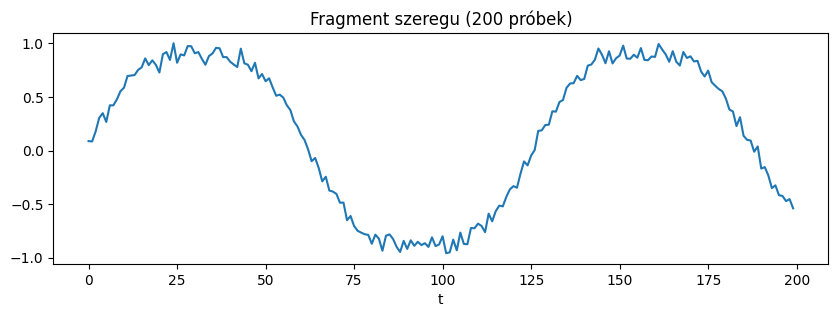

In [3]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1 * np.sin(3 * t) + 0.05 * np.random.randn(n)
    return y.astype(np.float32)


seria = generuj_szereg()
plt.figure(figsize=(10, 3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)')
plt.xlabel('t')
plt.show()

## 3. Okna wejście-cel


In [4]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i + okno])
        Y.append(seria[i + okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y


def przygotuj_dane(okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8 * len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte


OKNO = 30
Xtr, Ytr, Xte, Yte = przygotuj_dane(OKNO)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


## 4. Model RNN


In [5]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

## 5. Pętla uczenia i model bazowy


In [6]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist, hist_tr = [], []
    n = len(Xtr)
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            hist_tr.append(strata(model(Xtr), Ytr).item())
            hist.append(strata(model(Xte), Yte).item())
    return hist, hist_tr


model = ModelRNN(hidden=32, typ='RNN')
hist, hist_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30)
print(f'Strata test: {hist[0]:.4f} -> {hist[-1]:.4f}')
print(f'Test MSE (średnia z 5 ostatnich epok): {np.mean(hist[-5:]):.5f}')
print('Liczba parametrów:', sum(p.numel() for p in model.parameters()))

Strata test: 0.0078 -> 0.0038
Test MSE (średnia z 5 ostatnich epok): 0.00386
Liczba parametrów: 1153


## 6. Heurystyka "ostatnia próbka"


In [7]:
mse_heur = ((Yte - Xte[:, -1]) ** 2).mean().item()
print(f'MSE heurystyki "ostatnia próbka" (OKNO=30): {mse_heur:.5f}')

MSE heurystyki "ostatnia próbka" (OKNO=30): 0.00631


## 7. Krzywe uczenia modelu bazowego

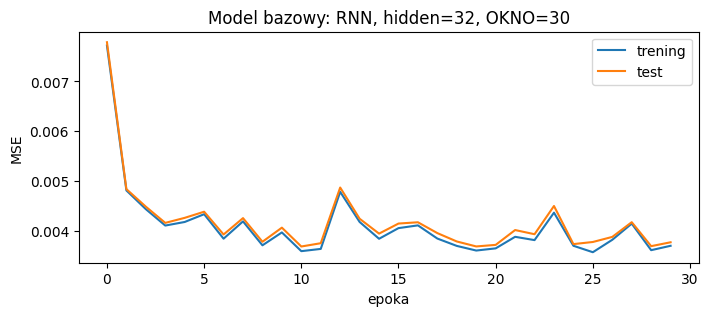

In [8]:
plt.figure(figsize=(8, 3))
plt.plot(hist_tr, label='trening')
plt.plot(hist, label='test')
plt.title('Model bazowy: RNN, hidden=32, OKNO=30')
plt.xlabel('epoka')
plt.ylabel('MSE')
plt.legend()
plt.show()

## 8. Predykcja modelu bazowego vs rzeczywistość

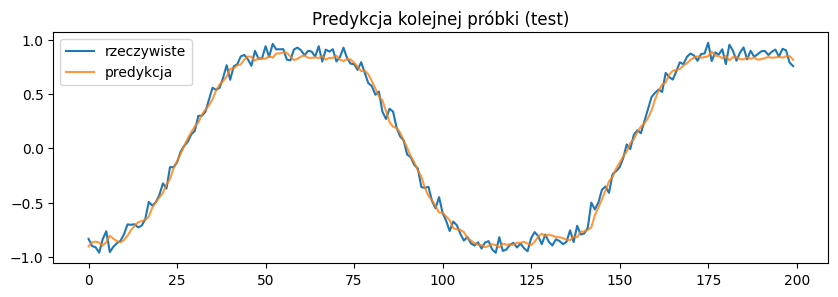

In [9]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10, 3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend()
plt.title('Predykcja kolejnej próbki (test)')
plt.show()

## 9. Przygotowanie eksperymentów


In [10]:
EPOKI = 20
LR = 1e-2
BATCH = 64
ZIARNA = [0, 1, 2]
KOLORY = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']

dane = {}
wyniki = {}


def dane_okna(okno):
    if okno not in dane:
        dane[okno] = przygotuj_dane(okno)
    return dane[okno]


def heurystyka(okno):
    _, _, Xte_o, Yte_o = dane_okna(okno)
    return ((Yte_o - Xte_o[:, -1]) ** 2).mean().item()


def uruchom(typ, hidden, okno):
    klucz = (typ, hidden, okno)
    if klucz in wyniki:
        return wyniki[klucz]
    Xtr_o, Ytr_o, Xte_o, Yte_o = dane_okna(okno)
    mse, mse_tr, czasy, h_te, h_tr, modele = [], [], [], [], [], []
    for seed in ZIARNA:
        torch.manual_seed(seed)
        m = ModelRNN(hidden=hidden, typ=typ)
        t0 = time.perf_counter()
        h, ht = trenuj(m, Xtr_o, Ytr_o, Xte_o, Yte_o,
                       epoki=EPOKI, lr=LR, batch=BATCH)
        czasy.append(time.perf_counter() - t0)
        mse.append(np.mean(h[-5:]))
        mse_tr.append(np.mean(ht[-5:]))
        h_te.append(h)
        h_tr.append(ht)
        modele.append(m)
    wyniki[klucz] = {
        'parametry': sum(p.numel() for p in m.parameters()),
        'mse': mse,
        'mse_sr': np.mean(mse),
        'mse_std': np.std(mse),
        'mse_tr': np.mean(mse_tr),
        'czas': np.mean(czasy),
        'hist_te': np.mean(h_te, axis=0),
        'hist_tr': np.mean(h_tr, axis=0),
        'model_0': modele[0],
    }
    return wyniki[klucz]


def tabela(konfiguracje, okna_heur):
    wiersze = []
    for o in okna_heur:
        wiersze.append({
            'konfiguracja': f'ostatnia próbka (OKNO={o})',
            'parametry': '-',
            'test MSE': f'{heurystyka(o):.5f}',
            'czas [s]': '-',
        })
    for typ, hidden, okno in konfiguracje:
        w = uruchom(typ, hidden, okno)
        wiersze.append({
            'konfiguracja': f'{typ}, hidden={hidden}, OKNO={okno}',
            'parametry': w['parametry'],
            'test MSE': f"{w['mse_sr']:.5f} ± {w['mse_std']:.5f}",
            'czas [s]': f"{w['czas']:.1f}",
        })
    print(pd.DataFrame(wiersze).to_string(index=False))


def wykres_test(serie, tytul):
    plt.figure(figsize=(8, 4))
    for klucz, etykieta, kolor, styl in serie:
        plt.plot(range(1, EPOKI + 1), wyniki[klucz]['hist_te'],
                 color=kolor, linestyle=styl, linewidth=2, label=etykieta)
    plt.yscale('log')
    plt.xticks([1] + list(range(5, EPOKI + 1, 5)))
    plt.title(tytul)
    plt.xlabel('epoka')
    plt.ylabel('test MSE (skala log.)')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## 10. Hipotezy

**Eksperyment A.** Zwiększenie liczby jednostek z 8 do 64 powinno obniżyć test MSE, ale coraz mniej. Dla tak prostego sygnału różnica między `hidden=32` i `hidden=64` może mieścić się w rozrzucie między ziarnami.

**Eksperyment B.** Wydłużenie okna z 10 do 60 powinno poprawić wynik, bo model widzi większą część okresu sygnału (ok. 126 próbek). Przy `OKNO=120` poprawa będzie prawdopodobnie niewielka albo wynik lekko się pogorszy.

## 11. Eksperyment A - liczba jednostek


In [11]:
konf_A = [('GRU', h, 30) for h in [8, 16, 32, 64]]
tabela(konf_A, [30])

             konfiguracja parametry          test MSE czas [s]
ostatnia próbka (OKNO=30)         -           0.00631        -
   GRU, hidden=8, OKNO=30       273 0.00380 ± 0.00004      6.2
  GRU, hidden=16, OKNO=30       929 0.00374 ± 0.00002      6.3
  GRU, hidden=32, OKNO=30      3393 0.00376 ± 0.00001      7.5
  GRU, hidden=64, OKNO=30     12929 0.00375 ± 0.00008     11.1


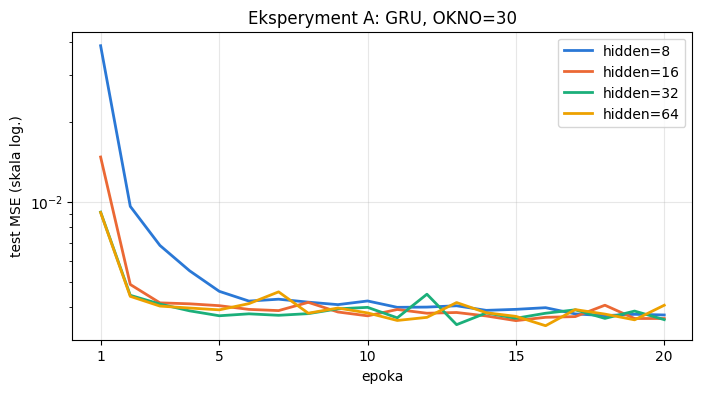

In [12]:
wykres_test(
    [(k, f'hidden={k[1]}', KOLORY[i], '-') for i, k in enumerate(konf_A)],
    'Eksperyment A: GRU, OKNO=30',
)

## 12. Eksperyment B - długość okna


In [13]:
konf_B = [('GRU', 32, o) for o in [10, 30, 60, 120]]
tabela(konf_B, [10, 30, 60, 120])

              konfiguracja parametry          test MSE czas [s]
 ostatnia próbka (OKNO=10)         -           0.00628        -
 ostatnia próbka (OKNO=30)         -           0.00631        -
 ostatnia próbka (OKNO=60)         -           0.00633        -
ostatnia próbka (OKNO=120)         -           0.00631        -
   GRU, hidden=32, OKNO=10      3393 0.00414 ± 0.00019      3.4
   GRU, hidden=32, OKNO=30      3393 0.00376 ± 0.00001      7.5
   GRU, hidden=32, OKNO=60      3393 0.00343 ± 0.00021     14.5
  GRU, hidden=32, OKNO=120      3393 0.00344 ± 0.00019     26.8


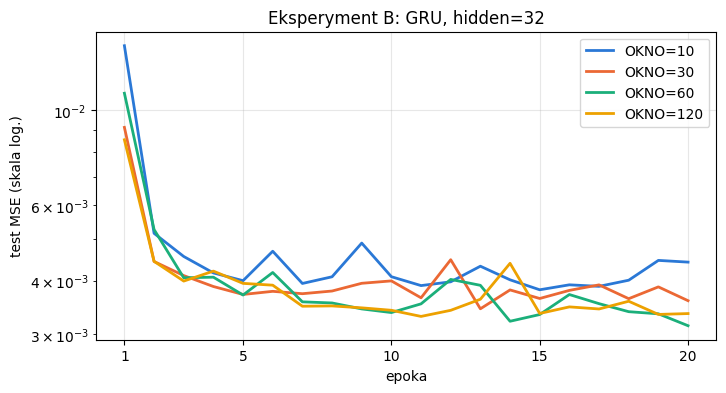

In [14]:
wykres_test(
    [(k, f'OKNO={k[2]}', KOLORY[i], '-') for i, k in enumerate(konf_B)],
    'Eksperyment B: GRU, hidden=32',
)

## 13. Eksperyment C - typ komórki


In [15]:
konf_C = [(t, 32, o) for o in [10, 120] for t in ['RNN', 'LSTM', 'GRU']]
tabela(konf_C, [10, 120])

              konfiguracja parametry          test MSE czas [s]
 ostatnia próbka (OKNO=10)         -           0.00628        -
ostatnia próbka (OKNO=120)         -           0.00631        -
   RNN, hidden=32, OKNO=10      1153 0.00417 ± 0.00025      1.6
  LSTM, hidden=32, OKNO=10      4513 0.00415 ± 0.00011      2.8
   GRU, hidden=32, OKNO=10      3393 0.00414 ± 0.00019      3.4
  RNN, hidden=32, OKNO=120      1153 0.00400 ± 0.00001     11.4
 LSTM, hidden=32, OKNO=120      4513 0.00375 ± 0.00013     16.5
  GRU, hidden=32, OKNO=120      3393 0.00344 ± 0.00019     26.8


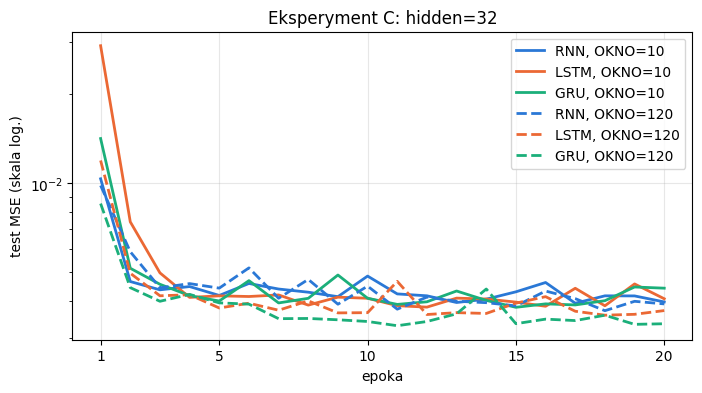

In [16]:
kolor_typu = {'RNN': KOLORY[0], 'LSTM': KOLORY[1], 'GRU': KOLORY[2]}
styl_okna = {10: '-', 120: '--'}
wykres_test(
    [(k, f'{k[0]}, OKNO={k[2]}', kolor_typu[k[0]], styl_okna[k[2]])
     for k in konf_C],
    'Eksperyment C: hidden=32',
)

## 14. Najlepsza konfiguracja


Najlepsza konfiguracja: GRU, hidden=32, OKNO=60
test MSE = 0.00343 ± 0.00021
train MSE = 0.00339


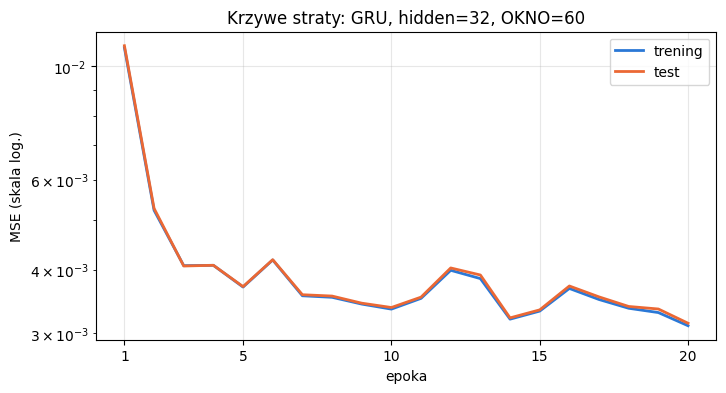

In [17]:
najlepsza = min(wyniki, key=lambda k: wyniki[k]['mse_sr'])
typ_b, hidden_b, okno_b = najlepsza
w_b = wyniki[najlepsza]
print(f'Najlepsza konfiguracja: {typ_b}, hidden={hidden_b}, OKNO={okno_b}')
print(f"test MSE = {w_b['mse_sr']:.5f} ± {w_b['mse_std']:.5f}")
print(f"train MSE = {w_b['mse_tr']:.5f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOKI + 1), w_b['hist_tr'], color=KOLORY[0],
         linewidth=2, label='trening')
plt.plot(range(1, EPOKI + 1), w_b['hist_te'], color=KOLORY[1],
         linewidth=2, label='test')
plt.yscale('log')
plt.xticks([1] + list(range(5, EPOKI + 1, 5)))
plt.title(f'Krzywe straty: {typ_b}, hidden={hidden_b}, OKNO={okno_b}')
plt.xlabel('epoka')
plt.ylabel('MSE (skala log.)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

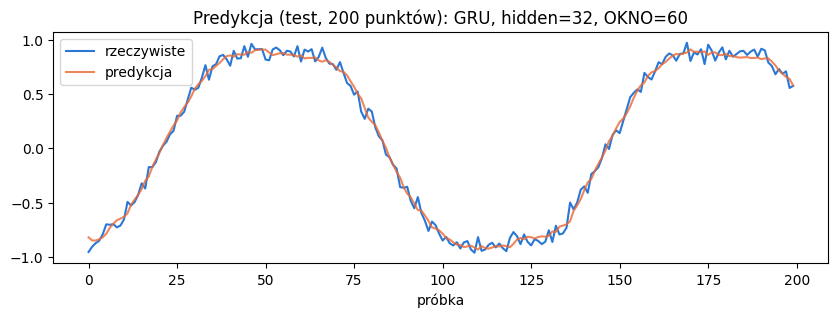

In [18]:
_, _, Xte_b, Yte_b = dane_okna(okno_b)
model_b = w_b['model_0']
model_b.eval()
with torch.no_grad():
    pred_b = model_b(Xte_b).cpu().numpy().ravel()
prawdziwe_b = Yte_b.cpu().numpy().ravel()

plt.figure(figsize=(10, 3))
plt.plot(prawdziwe_b[:200], color=KOLORY[0], label='rzeczywiste')
plt.plot(pred_b[:200], color=KOLORY[1], alpha=0.8, label='predykcja')
plt.title(f'Predykcja (test, 200 punktów): {typ_b}, hidden={hidden_b}, '
          f'OKNO={okno_b}')
plt.xlabel('próbka')
plt.legend()
plt.show()